=== Результати для SLIC ===
Час виконання: 0.127 сек
Boundary Recall (BR): 0.5649 (чим вище, тим краще)
Undersegmentation Error (UE): 0.1697 (чим нижче, тим краще)


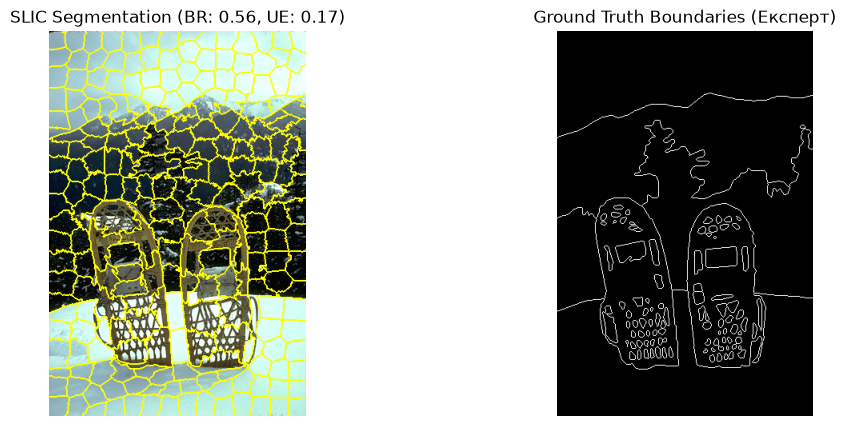

In [2]:
import os
import cv2
import matplotlib.pyplot as plt
from skimage.segmentation import slic, mark_boundaries
import metrics  # Наш файл metrics.py

# 1. Шляхи до файлів
image_id = "2018"  # Заміни на номер картинки, яку ти закинув
img_path = f"data/raw/{image_id}.jpg"
gt_path = f"data/ground_truth/{image_id}.mat"

if os.path.exists(img_path) and os.path.exists(gt_path):
    # 2. Завантажуємо зображення та розмітку
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    gt_segmentations, gt_boundaries = metrics.load_bsds500_gt(gt_path)
    # Беремо розмітку першого експерта для тесту
    first_gt_seg = gt_segmentations[0]
    first_gt_bound = gt_boundaries[0]
    
    # 3. Запускаємо SLIC
    labels_slic, time_slic = metrics.benchmark_algorithm(slic, img, n_segments=300, compactness=10, start_label=1)
    
    # 4. Рахуємо метрики
    br = metrics.compute_boundary_recall(first_gt_bound, labels_slic, tolerance=2)
    ue = metrics.compute_undersegmentation_error(first_gt_seg, labels_slic)
    
    print(f"=== Результати для SLIC ===")
    print(f"Час виконання: {time_slic:.3f} сек")
    print(f"Boundary Recall (BR): {br:.4f} (чим вище, тим краще)")
    print(f"Undersegmentation Error (UE): {ue:.4f} (чим нижче, тим краще)")
    
    # 5. Візуалізація
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(mark_boundaries(img, labels_slic))
    axes[0].set_title(f"SLIC Segmentation (BR: {br:.2f}, UE: {ue:.2f})")
    
    axes[1].imshow(first_gt_bound, cmap='gray')
    axes[1].set_title("Ground Truth Boundaries (Експерт)")
    
    for ax in axes:
        ax.axis('off')
    plt.show()
else:
    print(f"Файли {img_path} або {gt_path} не знайдено! Перевір назви у папках data/raw та data/ground_truth.")

=== Порівняльна таблиця результатів ===
   Algorithm     Time       BR       UE
        SLIC 0.103425 0.564893 0.169720
Felzenszwalb 0.132077 0.861575 0.105485
  Quickshift 0.566363 0.946397 0.100343
   Watershed 0.042265 0.666798 0.151502


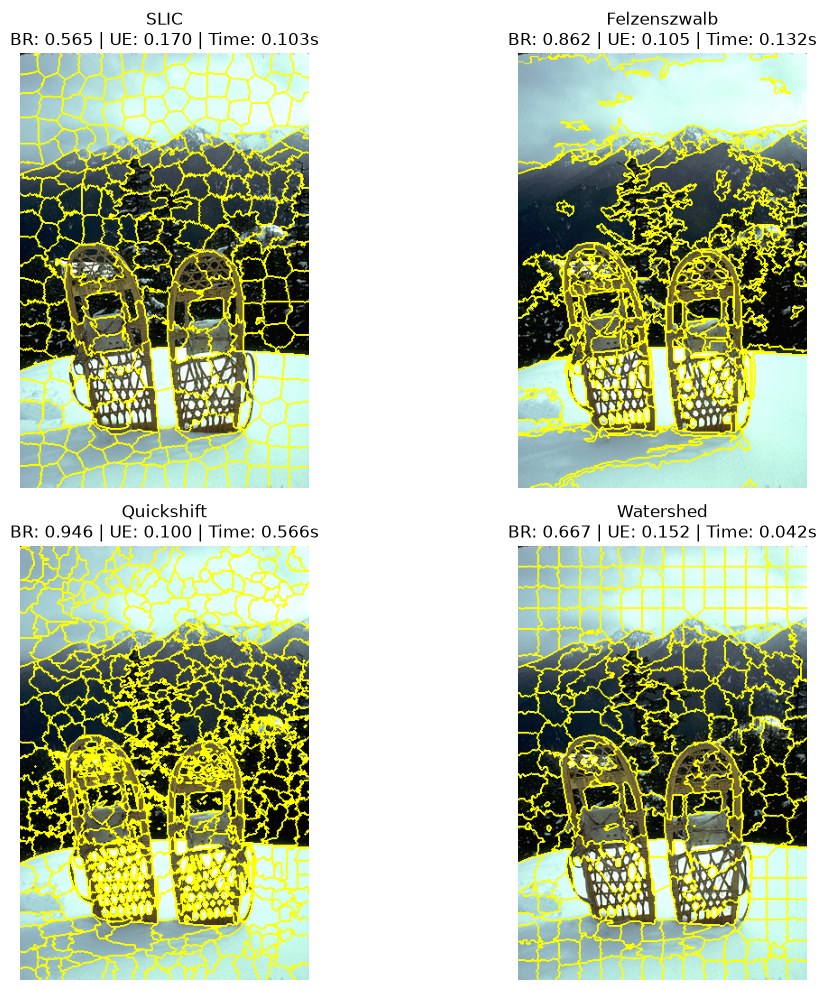

In [4]:
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from skimage.segmentation import slic, felzenszwalb, quickshift, watershed, mark_boundaries
from skimage.filters import sobel
from skimage.color import rgb2gray
import metrics

# 1. Завантаження кадру
image_id = "2018"  # або будь-який інший ID
img_path = f"data/raw/{image_id}.jpg"
gt_path = f"data/ground_truth/{image_id}.mat"

img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gt_segmentations, gt_boundaries = metrics.load_bsds500_gt(gt_path)
gt_seg = gt_segmentations[0]
gt_bound = gt_boundaries[0]

# 2. Запуск 4 алгоритмів
results = []

# SLIC
labels_slic, t_slic = metrics.benchmark_algorithm(slic, img, n_segments=300, compactness=10, start_label=1)
results.append({
    'Algorithm': 'SLIC', 'Labels': labels_slic, 'Time': t_slic,
    'BR': metrics.compute_boundary_recall(gt_bound, labels_slic),
    'UE': metrics.compute_undersegmentation_error(gt_seg, labels_slic)
})

# Felzenszwalb
labels_felz, t_felz = metrics.benchmark_algorithm(felzenszwalb, img, scale=100, sigma=0.5, min_size=50)
results.append({
    'Algorithm': 'Felzenszwalb', 'Labels': labels_felz, 'Time': t_felz,
    'BR': metrics.compute_boundary_recall(gt_bound, labels_felz),
    'UE': metrics.compute_undersegmentation_error(gt_seg, labels_felz)
})

# Quickshift
labels_quick, t_quick = metrics.benchmark_algorithm(quickshift, img, kernel_size=3, max_dist=6, ratio=0.5)
results.append({
    'Algorithm': 'Quickshift', 'Labels': labels_quick, 'Time': t_quick,
    'BR': metrics.compute_boundary_recall(gt_bound, labels_quick),
    'UE': metrics.compute_undersegmentation_error(gt_seg, labels_quick)
})

# Watershed
gradient = sobel(rgb2gray(img))
labels_water, t_water = metrics.benchmark_algorithm(watershed, gradient, markers=300, compactness=0.001)
results.append({
    'Algorithm': 'Watershed', 'Labels': labels_water, 'Time': t_water,
    'BR': metrics.compute_boundary_recall(gt_bound, labels_water),
    'UE': metrics.compute_undersegmentation_error(gt_seg, labels_water)
})

# 3. Вивід порівняльної таблиці
df = pd.DataFrame(results)[['Algorithm', 'Time', 'BR', 'UE']]
print("=== Порівняльна таблиця результатів ===")
print(df.to_string(index=False))

# 4. Візуалізація сіток
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, res in enumerate(results):
    axes[i].imshow(mark_boundaries(img, res['Labels']))
    axes[i].set_title(f"{res['Algorithm']}\nBR: {res['BR']:.3f} | UE: {res['UE']:.3f} | Time: {res['Time']:.3f}s")
    axes[i].axis('off')

plt.tight_layout()
plt.show()